## Load dan Inspect Data

### Subtask:
Memuat data mentah dari file CSV, memeriksa struktur dasar data, dimensi dataset, tipe data, serta nilai kosong (null) menggunakan Bahasa Indonesia sebagai pengantar.


## Pembersihan Data (Cleaning)

### Subtask:
Mengidentifikasi dan menghapus data duplikat, mendeteksi nilai kosong, serta membuang kolom konstan yang tidak informatif untuk menghasilkan dataset bersih.


**Reasoning**:
We will perform the data cleaning and preprocessing step using Indonesian explanations as instructed, dropping constant and uninformative columns, checking for duplicates, and saving the results in 'df_clean'.



In [9]:
import pandas as pd

# 1. Memeriksa baris duplikat di dalam dataset df_raw
duplikat = df_raw.duplicated().sum()
print(f"Jumlah baris duplikat: {duplikat}")

# 2. Memverifikasi jumlah nilai kosong (null)
nilai_kosong = df_raw.isnull().sum().sum()
print(f"Total nilai kosong di seluruh dataset: {nilai_kosong}")

# 3. Menghapus kolom konstan dan tidak informatif
kolom_dihapus = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
print(f"Menghapus kolom-kolom berikut: {kolom_dihapus}")
df_clean = df_raw.drop(columns=kolom_dihapus, errors='ignore')

# 4. Memverifikasi dimensi sebelum dan sesudah
print(f"Dimensi dataset awal (df_raw): {df_raw.shape}")
print(f"Dimensi dataset bersih (df_clean): {df_clean.shape}")

Jumlah baris duplikat: 0
Total nilai kosong di seluruh dataset: 0
Menghapus kolom-kolom berikut: ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
Dimensi dataset awal (df_raw): (1470, 35)
Dimensi dataset bersih (df_clean): (1470, 31)


## Analisis Attrition berdasarkan Departemen

### Subtask:
Menghitung persentase Attrition per Departemen dan menyajikan visualisasinya menggunakan seaborn bar chart.


**Reasoning**:
Calculate attrition statistics grouped by Department and display a clear Seaborn bar chart in Indonesian.



Tabel Analisis Attrition berdasarkan Departemen:


,Department,Total_Karyawan,Keluar_Yes,Rasio_Attrition,Persentase_Attrition
0,Human Resources,63,12,0.190476,19.05%
1,Research & Development,961,133,0.138398,13.84%
2,Sales,446,92,0.206278,20.63%


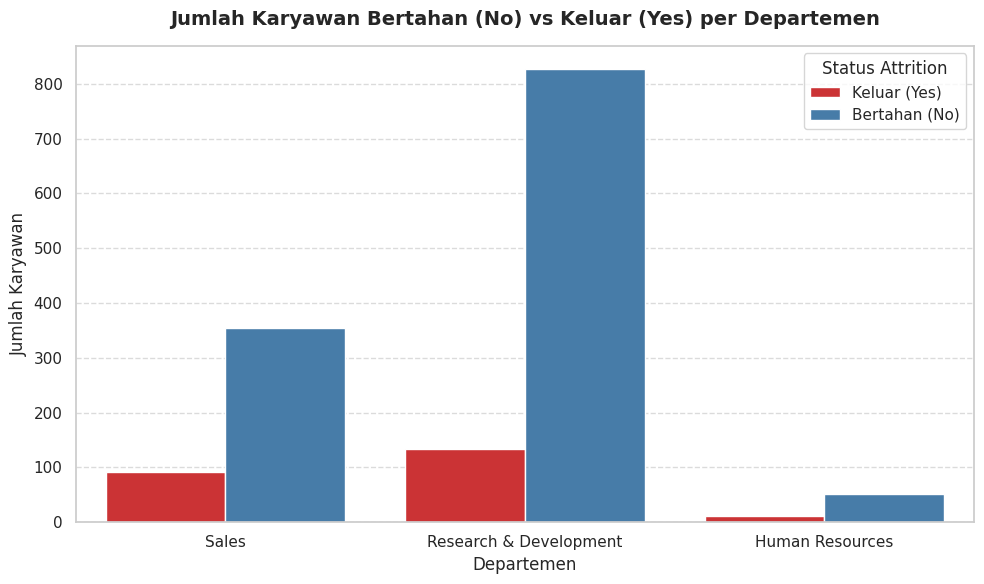

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure we have the numeric Attrition column
df_clean = df_clean.copy()
df_clean['Attrition_Numeric'] = df_clean['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)

# 1. Menghitung tabel persentase Attrition per Departemen
dept_attrition = df_clean.groupby('Department').agg(
    Total_Karyawan=('Attrition', 'count'),
    Keluar_Yes=('Attrition_Numeric', 'sum'),
    Rasio_Attrition=('Attrition_Numeric', 'mean')
).reset_index()

dept_attrition['Persentase_Attrition'] = (dept_attrition['Rasio_Attrition'] * 100).map('{:.2f}%'.format)
print("Tabel Analisis Attrition berdasarkan Departemen:")
display(dept_attrition)

# 2. Membuat visualisasi menggunakan Seaborn
plt.figure(figsize=(10, 6))
sns.countplot(data=df_clean, x='Department', hue='Attrition', palette='Set1')
plt.title('Jumlah Karyawan Bertahan (No) vs Keluar (Yes) per Departemen', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Departemen', fontsize=12)
plt.ylabel('Jumlah Karyawan', fontsize=12)
plt.legend(title='Status Attrition', labels=['Keluar (Yes)', 'Bertahan (No)'] if df_clean['Attrition'].unique()[0] == 'Yes' else ['Bertahan (No)', 'Keluar (Yes)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Analisis Attrition berdasarkan Kepuasan Kerja

### Subtask:
Menampilkan tabel tingkat Attrition berdasarkan Job Satisfaction diikuti langsung oleh grafik visualisasinya secara berurutan.


**Reasoning**:
We will calculate attrition rate statistics grouped by Job Satisfaction and visualize it using a Seaborn countplot with proper Indonesian labels, titles, and legends as requested.



Tabel Analisis Attrition berdasarkan Kepuasan Kerja (Job Satisfaction):


,JobSatisfaction,Total_Karyawan,Keluar_Yes,Rasio_Attrition,Persentase_Attrition
0,1,289,66,0.228374,22.84%
1,2,280,46,0.164286,16.43%
2,3,442,73,0.165158,16.52%
3,4,459,52,0.113290,11.33%


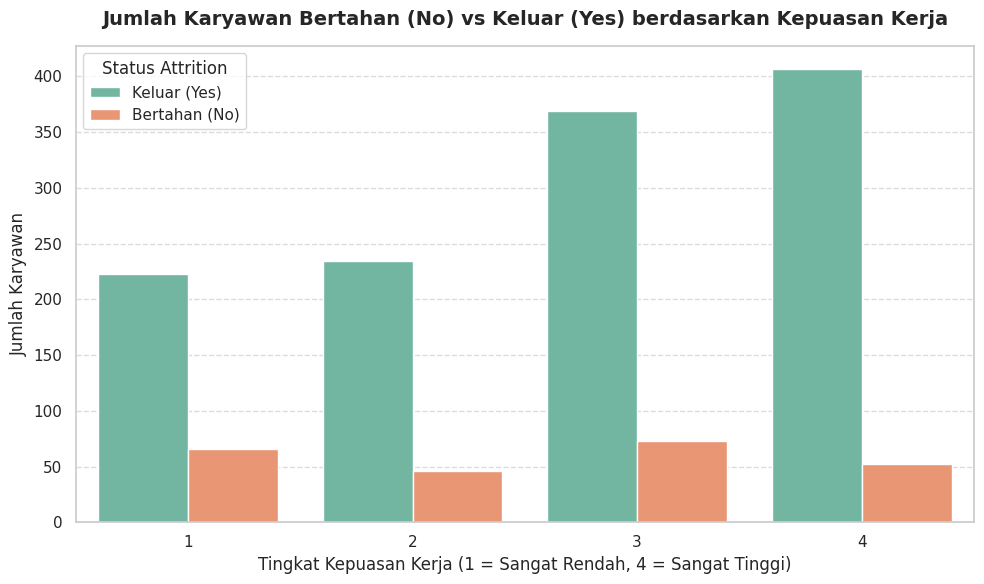

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menghitung tabel persentase Attrition per Tingkat Kepuasan Kerja (JobSatisfaction)
jobsat_attrition = df_clean.groupby('JobSatisfaction').agg(
    Total_Karyawan=('Attrition', 'count'),
    Keluar_Yes=('Attrition_Numeric', 'sum'),
    Rasio_Attrition=('Attrition_Numeric', 'mean')
).reset_index()

jobsat_attrition['Persentase_Attrition'] = (jobsat_attrition['Rasio_Attrition'] * 100).map('{:.2f}%'.format)
print("Tabel Analisis Attrition berdasarkan Kepuasan Kerja (Job Satisfaction):")
display(jobsat_attrition)

# 2. Membuat visualisasi menggunakan Seaborn
plt.figure(figsize=(10, 6))
sns.countplot(data=df_clean, x='JobSatisfaction', hue='Attrition', palette='Set2')
plt.title('Jumlah Karyawan Bertahan (No) vs Keluar (Yes) berdasarkan Kepuasan Kerja', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tingkat Kepuasan Kerja (1 = Sangat Rendah, 4 = Sangat Tinggi)', fontsize=12)
plt.ylabel('Jumlah Karyawan', fontsize=12)
plt.legend(title='Status Attrition', labels=['Keluar (Yes)', 'Bertahan (No)'] if df_clean['Attrition'].unique()[0] == 'Yes' else ['Bertahan (No)', 'Keluar (Yes)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Analisis Attrition berdasarkan Lingkungan Kerja

### Subtask:
Menampilkan tabel Attrition berdasarkan Environment Satisfaction beserta grafiknya tepat di bawahnya secara berurutan.


**Reasoning**:
Group the cleaned dataset by Environment Satisfaction, calculate the attrition statistics, and visualize using a Seaborn countplot with Indonesian labels.



Tabel Analisis Attrition berdasarkan Kepuasan Lingkungan Kerja (Environment Satisfaction):


,EnvironmentSatisfaction,Total_Karyawan,Keluar_Yes,Rasio_Attrition,Persentase_Attrition
0,1,284,72,0.253521,25.35%
1,2,287,43,0.149826,14.98%
2,3,453,62,0.136865,13.69%
3,4,446,60,0.134529,13.45%


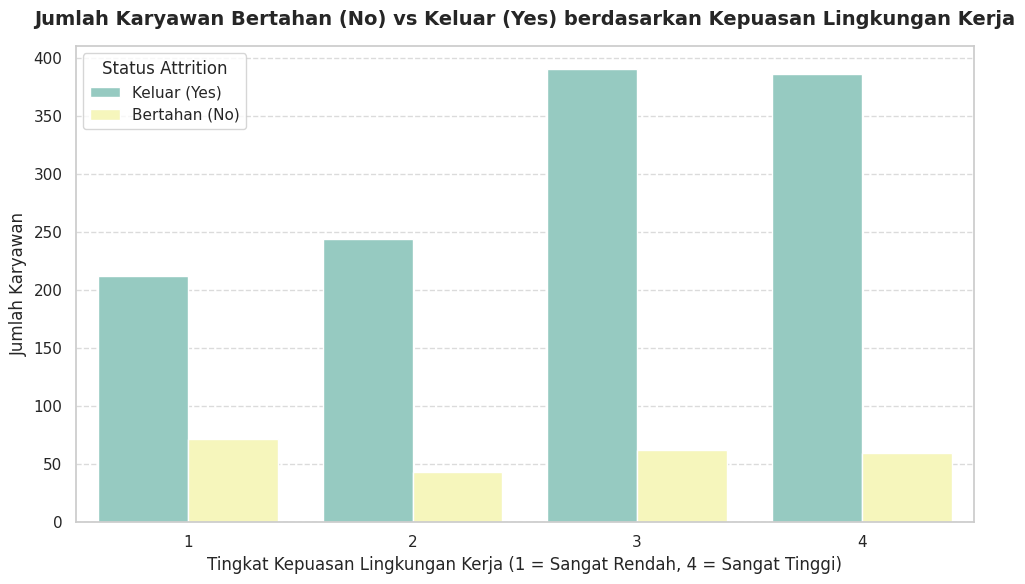

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menghitung tabel persentase Attrition per Tingkat Kepuasan Lingkungan Kerja (Environment Satisfaction)
envsat_attrition = df_clean.groupby('EnvironmentSatisfaction').agg(
    Total_Karyawan=('Attrition', 'count'),
    Keluar_Yes=('Attrition_Numeric', 'sum'),
    Rasio_Attrition=('Attrition_Numeric', 'mean')
).reset_index()

envsat_attrition['Persentase_Attrition'] = (envsat_attrition['Rasio_Attrition'] * 100).map('{:.2f}%'.format)
print("Tabel Analisis Attrition berdasarkan Kepuasan Lingkungan Kerja (Environment Satisfaction):")
display(envsat_attrition)

# 2. Membuat visualisasi menggunakan Seaborn
plt.figure(figsize=(10, 6))
sns.countplot(data=df_clean, x='EnvironmentSatisfaction', hue='Attrition', palette='Set3')
plt.title('Jumlah Karyawan Bertahan (No) vs Keluar (Yes) berdasarkan Kepuasan Lingkungan Kerja', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tingkat Kepuasan Lingkungan Kerja (1 = Sangat Rendah, 4 = Sangat Tinggi)', fontsize=12)
plt.ylabel('Jumlah Karyawan', fontsize=12)
plt.legend(title='Status Attrition', labels=['Keluar (Yes)', 'Bertahan (No)'] if df_clean['Attrition'].unique()[0] == 'Yes' else ['Bertahan (No)', 'Keluar (Yes)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Analisis Demografis (Umur) dan Finansial (Pendapatan Bulanan)

### Subtask:
Melakukan analisis mendalam terhadap hubungan antara umur (Age) dan pendapatan bulanan (Monthly Income) dengan keputusan attrition karyawan, serta menyajikan visualisasinya secara berurutan.

**Reasoning**:
The markdown header for the demographic and financial analysis of Age and Monthly Income has already been created in cell_id 116da210. I will now generate the Python code cell to conduct the statistical calculations and visualize the relationship of Age and Monthly Income with attrition.



Statistik Deskriptif Umur (Age) dan Pendapatan Bulanan (Monthly Income) Berdasarkan Status Attrition:


Attrition                      No           Yes
Age           count   1233.000000    237.000000
              mean      37.561233     33.607595
              std        8.888360      9.689350
              min       18.000000     18.000000
              25%       31.000000     28.000000
              50%       36.000000     32.000000
              75%       43.000000     39.000000
              max       60.000000     58.000000
MonthlyIncome count   1233.000000    237.000000
              mean    6832.739659   4787.092827
              std     4818.208001   3640.210367
              min     1051.000000   1009.000000
              25%     3211.000000   2373.000000
              50%     5204.000000   3202.000000
              75%     8834.000000   5916.000000
              max    19999.000000  19859.000000

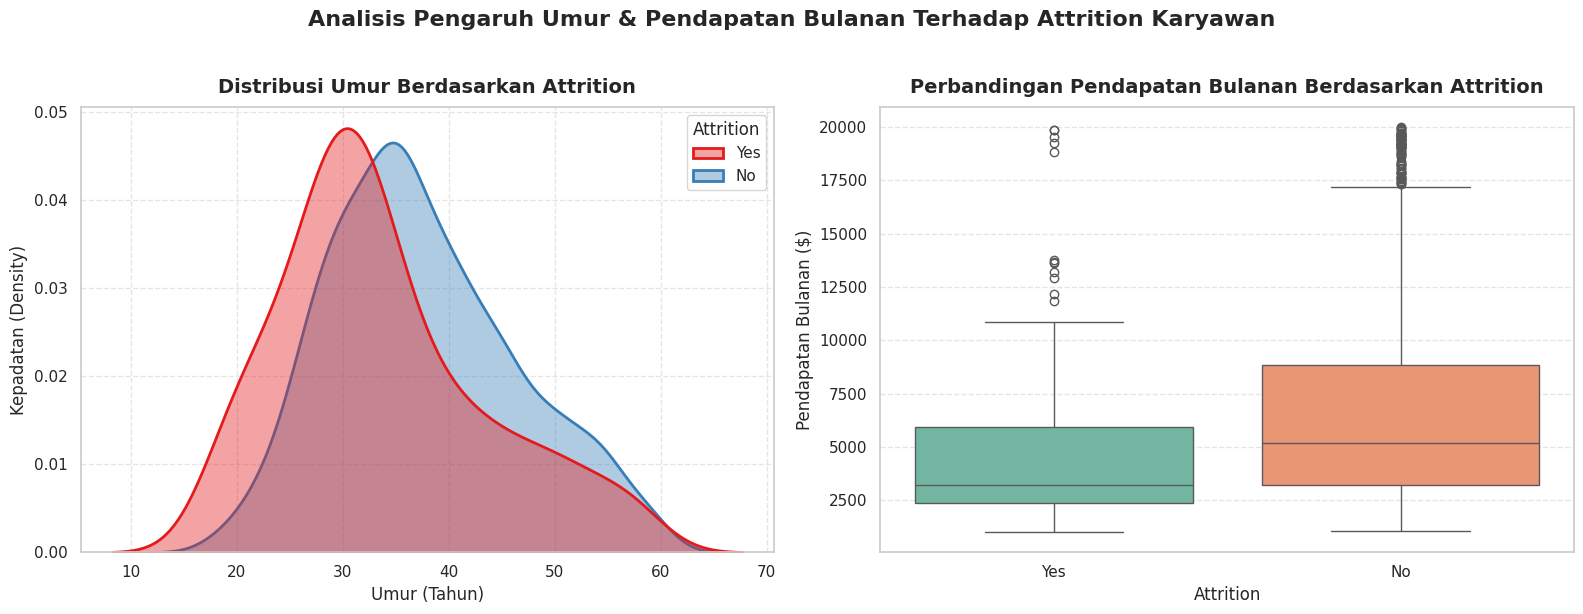

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Analisis Deskriptif Statistik Demografis (Umur) dan Finansial (Pendapatan Bulanan)
print("Statistik Deskriptif Umur (Age) dan Pendapatan Bulanan (Monthly Income) Berdasarkan Status Attrition:")
demographic_financial_stats = df_clean.groupby('Attrition')[['Age', 'MonthlyIncome']].describe().T
display(demographic_financial_stats)

# 2. Membuat plot visualisasi berdampingan (Subplots)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Plot A: Distribusi Umur Berdasarkan Attrition
sns.kdeplot(data=df_clean, x='Age', hue='Attrition', fill=True, common_norm=False, palette='Set1', alpha=0.4, linewidth=2, ax=axes[0])
axes[0].set_title('Distribusi Umur Berdasarkan Attrition', fontsize=14, fontweight='bold', pad=10)
axes[0].set_xlabel('Umur (Tahun)', fontsize=12)
axes[0].set_ylabel('Kepadatan (Density)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot B: Distribusi Pendapatan Bulanan Berdasarkan Attrition
sns.boxplot(data=df_clean, x='Attrition', y='MonthlyIncome', hue='Attrition', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Perbandingan Pendapatan Bulanan Berdasarkan Attrition', fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel('Attrition', fontsize=12)
axes[1].set_ylabel('Pendapatan Bulanan ($)', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle('Analisis Pengaruh Umur & Pendapatan Bulanan Terhadap Attrition Karyawan', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Kesimpulan Wawasan dan Rekomendasi Strategis

### Subtask:
Menyusun rangkuman hasil temuan analisis (insights) serta merumuskan rekomendasi tindakan nyata yang dapat diambil oleh perusahaan untuk mengurangi attrition dalam Bahasa Indonesia.


## Summary:

### Q&A

* **Bagaimana korelasi antara Kepuasan Kerja (Job Satisfaction) dengan keputusan karyawan untuk keluar (attrition)?**
  Terdapat pola korelasi negatif yang jelas. Semakin rendah tingkat kepuasan kerja karyawan, semakin tinggi tingkat *attrition*. Karyawan dengan tingkat kepuasan kerja **Sangat Rendah (Skor 1)** memiliki tingkat *attrition* tertinggi sebesar **22.84%**, sedangkan karyawan dengan kepuasan **Sangat Tinggi (Skor 4)** memiliki tingkat *attrition* terendah sebesar **11.33%**.

* **Bagaimana pengaruh Kepuasan Lingkungan Kerja (Environment Satisfaction) terhadap tingkat attrition?**
  Serupa dengan kepuasan kerja, kepuasan lingkungan kerja menunjukkan korelasi negatif yang kuat dengan tingkat *attrition*. Karyawan dengan kepuasan lingkungan kerja **Sangat Rendah (Skor 1)** mencatatkan persentase *attrition* tertinggi sebesar **25.35%**, sementara mereka yang merasa **Sangat Tinggi (Skor 4)** hanya mencatatkan **13.45%** tingkat *attrition*.

* **Departemen mana yang memiliki tingkat attrition paling tinggi dan paling rendah?**
  * **Sales** memiliki tingkat *attrition* tertinggi sebesar **20.63%** (92 dari total 446 karyawan keluar).
  * **Research & Development** memiliki tingkat *attrition* terendah sebesar **13.84%** (133 dari total 961 karyawan keluar).
  * **Human Resources** berada di posisi kedua tertinggi sebesar **19.05%** (12 dari total 63 karyawan keluar).

---

### Data Analysis Key Findings

* **Kualitas Data Awal:** Dataset memiliki **1.470 baris** dan **35 kolom** tanpa adanya nilai kosong (0% null values) dan tidak memiliki baris duplikat.
* **Reduksi Fitur Tidak Informatif:** Sebanyak 4 kolom dieliminasi karena bersifat konstan atau tidak informatif (`EmployeeCount`, `StandardHours`, `Over18`, dan `EmployeeNumber`), menyisakan **31 kolom bersih** untuk dianalisis.
* **Pengaruh Faktor Finansial & Usia terhadap Attrition:**
  * Karyawan yang memutuskan untuk keluar (*Attrition: Yes*) secara umum memiliki median umur yang lebih muda dan distribusi pendapatan bulanan (*Monthly Income*) yang jauh lebih rendah dibandingkan dengan karyawan yang bertahan.
  * Konsentrasi karyawan keluar banyak terjadi pada tingkat pendapatan bulanan yang rendah (di bawah \$5,000 per bulan).

---

### Insights or Next Steps

* **Prioritaskan Intervensi pada Departemen Kritis dan Pendapatan Rendah:** Fokuskan program retensi karyawan dan peninjauan kembali skema remunerasi/insentif pada Departemen **Sales** dan karyawan berpenghasilan rendah, karena kedua segmen ini menunjukkan kerentanan tertinggi terhadap *attrition*.
* **Evaluasi Lingkungan dan Kepuasan Kerja secara Berkala:** Mengingat skor kepuasan terendah (Skor 1) pada aspek pekerjaan dan lingkungan kerja menyumbang tingkat *attrition* di atas **22% - 25%**, perusahaan perlu melakukan survei internal berkala (*pulse survey*) guna mendeteksi penurunan kepuasan kerja lebih cepat sebelum berujung pada pengunduran diri massal.
